In [1]:
import pandas as pd
import torch
import tqdm
import numpy as np
import scipy.special as scipy_special

import matplotlib.pyplot as plt

from agfn.gym import MAG_HITL, LogReward
from agfn.policies import ForwardPolicyHITL, BackwardPolicyHITL

from agfn.gflownet import GFlowNet

from agfn.commons import is_mag

torch.manual_seed(42)

In [2]:
device = "cpu"
assert device == "cpu", "Currently, only CPU is supported"

## Load data

In [3]:
#data_path = "data/sachs7/sachs7_half.csv"
data_path = "data/sachs5/sachs5.csv"
#data_path = "data/sachs/sachs_half.csv"
data = pd.read_csv(data_path)
data = torch.tensor(data.values, dtype=torch.get_default_dtype(), device=device)

num_nodes = data.shape[1]

In [4]:
hidden_dim = 128
num_layers = 2

pf = ForwardPolicyHITL(num_nodes, hidden_dim, num_layers, device=device)
pb = BackwardPolicyHITL(device=device)

gfn = GFlowNet(pf, pb, criterion="cb", device=device)

In [5]:
log_reward = LogReward(data, device=device)
# from agfn.gym import LogRewardSlightlyComplex
# log_reward = LogRewardSlightlyComplex(num_nodes, device=device)

initial_state = MAG_HITL(num_nodes, 256, log_reward)
if isinstance(log_reward, LogReward):
    log_reward.warmup(gfn, initial_state=initial_state, num_batches=8)

In [6]:
state = gfn.sample(
    initial_state
)

p, s = state.parents_and_spouses

is_graph_mag, th = is_mag(p, s, return_th=True)
assert is_graph_mag.all(), (th.mean(), th)

## Train an AGFN

In [65]:
np.append(np.arange(2,11,3),11)

array([ 2,  5,  8, 11])

In [7]:
teste = gfn.train()
opt = torch.optim.Adam([
    {"params": gfn.pf.parameters(), "lr": 1e-3},
    {"params": gfn.log_z, "lr": 1e-1},
])

num_epochs = int(2500)

sch = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=num_epochs)

log_z_values = []

pbar = tqdm.tqdm(range(num_epochs))

for _ in pbar:
    initial_state = MAG_HITL(num_nodes, 256, log_reward)
    opt.zero_grad()
    loss = gfn(initial_state)
    loss.backward()
    opt.step()
    sch.step()

    log_z_values.append(gfn.log_z.detach().cpu().item())
    
    pbar.set_postfix(loss=loss.item())

100%|██████████████████████████████████████████████████████████████████| 2500/2500 [39:31<00:00,  1.05it/s, loss=0.467]


In [8]:
gfn.eval()
# Sample a lot of graphs and compute their relative frequencies
graphs = []
log_rewards = []

for _ in tqdm.trange(int(1e2)):
    initial_state = MAG_HITL(num_nodes, 256, log_reward)
    state = gfn.sample(initial_state)
    graphs.append(state.adjacency_matrix.cpu().numpy())
    log_rewards.append(state.log_reward().cpu().numpy())

graphs = np.concatenate(graphs, axis=0)
log_rewards = np.concatenate(log_rewards, axis=0)

100%|████████████████████████████████████████████████████████████████████████████████| 100/100 [00:33<00:00,  2.96it/s]


In [9]:
from agfn.gym import MAG

l = MAG.mag_to_pcalg(state.adjacency_matrix)
pag_no_llm = []
indices = torch.topk(state.log_reward(), k=10).indices
for i in indices:
    pag_no_llm.append(l[i])
for idx, tensor in enumerate(pag_no_llm):
    pd.DataFrame(tensor.numpy()).to_csv(f'mag/mag_agfn_sachs5/mag_agfn_{idx}.csv', index=None)
    #pd.DataFrame(tensor.numpy()).to_csv(f'mag/mag_agfn_sachs7/mag_agfn_{idx}.csv', index=None)
    #pd.DataFrame(tensor.numpy()).to_csv(f'mag/mag_agfn_sachs/mag_agfn_{idx}.csv', index=None)
    

In [10]:
_, indices, counts = np.unique(graphs, axis=0, return_counts=True, return_index=True)
empirical_freq = np.log(counts) - np.log(counts.sum())
expected_freq = log_rewards[indices] - scipy_special.logsumexp(log_rewards[indices])

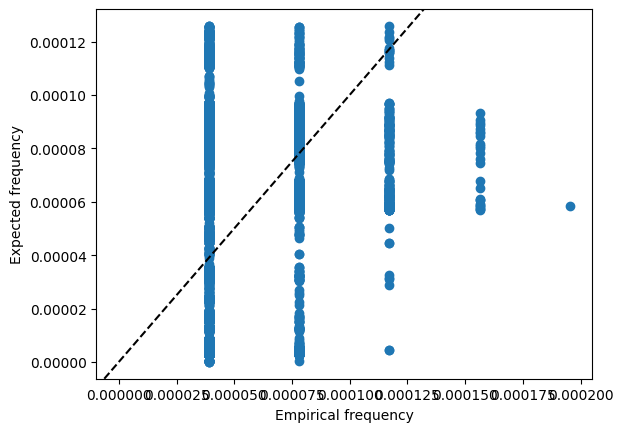

In [11]:
plt.scatter(
    np.exp(empirical_freq), np.exp(expected_freq)
)

plt.axline((0, 0), slope=1, color="black", linestyle="--")
plt.xlabel("Empirical frequency")
plt.ylabel("Expected frequency")

plt.show()

## Posterior update from human feedback

In [12]:
import networkx as nx

from agfn.commons import EdgeType
from agfn.hitl import (
    get_response_from_oracle, 
    find_next_query_from_reward_cross_entropy, 
    posterior_from_responses, 
    posterior_from_responses_pi_list,
    log_score_from_responses,
    find_next_query_from_entropy,
    find_next_query_from_entropy_pi_list,
    find_next_query_randomly,
    str_to_list,
    get_response_from_LLM_oracle
)

In [16]:
initial_state = MAG_HITL(num_nodes, 256, log_reward)

llm_oracle = pd.read_csv('llm_oracle/sachs5_gpt4o.txt', header=None)

num_feedbacks = initial_state.max_num_edges

queries = []
responses = []
pis = []
#pis.append(1 - 1e-3)
pi = 1 - 1e-3

for _ in tqdm.trange(2):
#for _ in tqdm.trange(10):
    # query = find_next_query_from_reward_cross_entropy(gfn, log_reward, queries, responses, num_nodes, pi=pi, num_iterations=2, mask_queried_edges=True)
    query = find_next_query_from_entropy_pi_list(queries, responses, num_nodes, pis=pis)

    # query = find_next_query_randomly(num_nodes)
    #response = feedback_from_oracle(query)
    response, pi = get_response_from_LLM_oracle(query, llm_oracle)
    queries.append(query)
    responses.append(response.value)
    pis.append(pi)

    gfn.set_posterior(posterior_from_responses_pi_list(responses, queries, initial_state.max_num_edges, pis=pis))

100%|███████████████████████████████████████████████████████████████████████████████████| 2/2 [00:00<00:00, 642.71it/s]


In [17]:
# Sample from the posterior
samples = gfn.sample(initial_state)

In [18]:
from agfn.gym import MAG

l_llm = MAG.mag_to_pcalg(samples.adjacency_matrix)
pag_llm = []
indices_llm = torch.topk(samples.log_reward(), k=10).indices
for i in indices_llm:
    pag_llm.append(l_llm[i])
for idx, tensor in enumerate(pag_llm):
    #pd.DataFrame(tensor.numpy()).to_csv(f'mag/mag_llm_sachs7/mag_llm_{idx}.csv', index=None)
    #pd.DataFrame(tensor.numpy()).to_csv(f'mag/mag_llm_sachs/mag_llm_{idx}.csv', index=None)
    pd.DataFrame(tensor.numpy()).to_csv(f'mag/mag_llm_sachs5/feedback_2/mag_llm_{idx}.csv', index=None)

In [19]:
from agfn.gym import MAG

num_feedbacks = initial_state.max_num_edges

feedbacks = np.append(np.arange(2,num_feedbacks,2),num_feedbacks)

initial_state = MAG_HITL(num_nodes, 256, log_reward)

llm_oracle = pd.read_csv('llm_oracle/sachs5_gpt4o.txt', header=None)


for fb in feedbacks:
    print(fb)
    queries = []
    responses = []
    pis = []
    pi = 1 - 1e-3

    for _ in tqdm.trange(fb):
        query = find_next_query_from_entropy_pi_list(queries, responses, num_nodes, pis=pis)

        # query = find_next_query_randomly(num_nodes)
        #response = feedback_from_oracle(query)
        response, pi = get_response_from_LLM_oracle(query, llm_oracle)
        queries.append(query)
        responses.append(response.value)
        pis.append(pi)

        gfn.set_posterior(posterior_from_responses_pi_list(responses, queries, initial_state.max_num_edges, pis=pis))

    samples = gfn.sample(initial_state)

    l_llm = MAG.mag_to_pcalg(samples.adjacency_matrix)
    pag_llm = []
    indices_llm = torch.topk(samples.log_reward(), k=10).indices
    for i in indices_llm:
        pag_llm.append(l_llm[i])
    for idx, tensor in enumerate(pag_llm):
        #print(tensor,idx)
        #pd.DataFrame(tensor.numpy()).to_csv(f'mag/mag_llm_sachs7/feedback_{fb}/mag_llm_{idx}.csv', index=None)
        #pd.DataFrame(tensor.numpy()).to_csv(f'mag/mag_llm_sachs/feedback_{fb}/mag_llm_{idx}.csv', index=None)
        pd.DataFrame(tensor.numpy()).to_csv(f'mag/mag_llm_sachs5/feedback_{fb}/mag_llm_{idx}.csv', index=None)

2


100%|███████████████████████████████████████████████████████████████████████████████████| 2/2 [00:00<00:00, 696.67it/s]


4


100%|██████████████████████████████████████████████████████████████████████████████████| 4/4 [00:00<00:00, 2879.22it/s]


6


100%|██████████████████████████████████████████████████████████████████████████████████| 6/6 [00:00<00:00, 2740.78it/s]


8


100%|██████████████████████████████████████████████████████████████████████████████████| 8/8 [00:00<00:00, 3945.72it/s]


10


100%|████████████████████████████████████████████████████████████████████████████████| 10/10 [00:00<00:00, 3461.50it/s]


In [16]:
initial_scores = samples.log_reward()
scores = log_score_from_responses(samples, queries, responses, log_reward_coef=1/(pi * num_feedbacks))
_, largest_reward_samples = torch.topk(scores, k=100)

adjacency_matrices = samples.adjacency_matrix.cpu().numpy()
adjacency_matrices = np.unique(adjacency_matrices[largest_reward_samples], axis=0)

for i in range(len(adjacency_matrices)):
    g = nx.from_numpy_array(adjacency_matrices[i], create_using=nx.MultiDiGraph)
    layout = nx.planar_layout(g)
    plt.figure(figsize=(4, 4))
    nx.draw(g, pos=layout, with_labels=True)
    plt.show()

responses: tensor([[2],
        [2],
        [2],
        [2],
        [2],
        [2],
        [2],
        [2],
        [2],
        [2],
        [2],
        [2],
        [2],
        [2],
        [2],
        [2],
        [2],
        [2],
        [2],
        [2],
        [2]])


NetworkXException: G is not planar.